# 01. Análisis exploratorio de datos

Dataset público *Medical Appointment No Shows* (Hoppen, 2016). Objetivo: entender la composición de la muestra, detectar problemas de calidad y formular hipótesis sobre qué variables predicen la inasistencia.

In [1]:
import sys, json, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.utils import cargar_config, ruta, guardar_json, leer_json
CFG = cargar_config()
FIG = ruta(CFG["rutas"]["figuras"]); MET = ruta(CFG["rutas"]["metricas"])
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
C1, C2, C3, C4 = "#1F3A5F", "#C0504D", "#7F7F7F", "#E1A93B"
def guardar(nombre):
    plt.tight_layout(); plt.savefig(FIG / nombre, bbox_inches="tight"); plt.show()
from src.data_processing import cargar_crudos, limpiar, agregar_historial

In [2]:
crudo = cargar_crudos(CFG['rutas']['datos_crudos'])
print(crudo.shape); crudo.head()

2026-09-26 02:32:02 | INFO | priorizacion | datos crudos cargados: 110527 filas


(110527, 14)


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


## Calidad de datos
Se revisan valores faltantes, duplicados, edades imposibles y fechas inconsistentes.

In [3]:
calidad = {'filas': len(crudo), 'pacientes': crudo.PatientId.nunique(), 'faltantes': int(crudo.isna().sum().sum()),
           'citas_duplicadas': int(crudo.AppointmentID.duplicated().sum()), 'edad_negativa': int((crudo.Age < 0).sum()),
           'edad_mayor_100': int((crudo.Age > 100).sum()), 'handcap_mayor_1': int((crudo.Handcap > 1).sum())}
df = agregar_historial(limpiar(crudo))
calidad['antelacion_negativa_corregida'] = int(((pd.to_datetime(crudo.AppointmentDay).dt.normalize() - pd.to_datetime(crudo.ScheduledDay).dt.normalize()).dt.days < 0).sum())
calidad

2026-09-26 02:32:03 | INFO | priorizacion | limpieza: 1 edades negativas eliminadas, 5 antelaciones negativas llevadas a 0


{'filas': 110527,
 'pacientes': 62299,
 'faltantes': 0,
 'citas_duplicadas': 0,
 'edad_negativa': 1,
 'edad_mayor_100': 7,
 'handcap_mayor_1': 199,
 'antelacion_negativa_corregida': 5}

In [4]:
desc = df[['Age','lead_time_days','prior_appts','prior_noshow_rate','Scholarship','Hipertension','Diabetes','Alcoholism','Handcap','SMS_received','gender_f','no_show']].describe().T.round(3)
desc

,count,mean,std,min,25%,50%,75%,max
Age,110526.0,37.089,23.110,0.0,18.0,37.0,55.0,115.0
lead_time_days,110526.0,10.184,15.255,0.0,0.0,4.0,15.0,179.0
prior_appts,110526.0,0.893,3.645,0.0,0.0,0.0,1.0,83.0
prior_noshow_rate,110526.0,0.055,0.204,0.0,0.0,0.0,0.0,1.0
Scholarship,110526.0,0.098,0.298,0.0,0.0,0.0,0.0,1.0
Hipertension,110526.0,0.197,0.398,0.0,0.0,0.0,0.0,1.0
Diabetes,110526.0,0.072,0.258,0.0,0.0,0.0,0.0,1.0
Alcoholism,110526.0,0.030,0.172,0.0,0.0,0.0,0.0,1.0
Handcap,110526.0,0.020,0.141,0.0,0.0,0.0,0.0,1.0
SMS_received,110526.0,0.321,0.467,0.0,0.0,0.0,1.0,1.0


## Visualizaciones

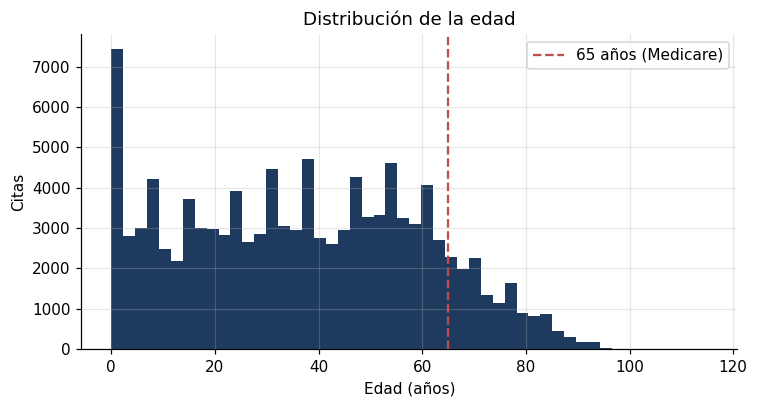

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(df.Age, bins=50, color=C1)
ax.axvline(65, color=C2, ls='--', label='65 años (Medicare)')
ax.set_xlabel('Edad (años)'); ax.set_ylabel('Citas'); ax.set_title('Distribución de la edad'); ax.legend()
guardar('01_edad.png')

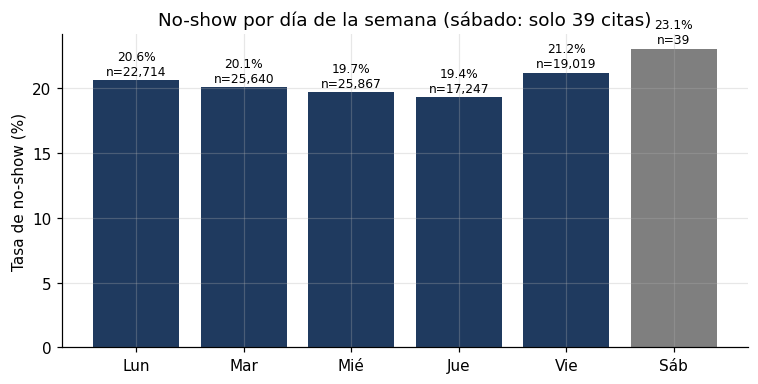

In [6]:
dias = ['Lun','Mar','Mié','Jue','Vie','Sáb']
t = df.groupby('appt_dow')['no_show'].agg(['mean','size'])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar([dias[i] for i in t.index], 100*t['mean'], color=[C3 if n < 100 else C1 for n in t['size']])
for i,(m,n) in enumerate(zip(t['mean'], t['size'])): ax.text(i, 100*m+0.4, f'{100*m:.1f}%\nn={n:,}', ha='center', fontsize=8)
ax.set_ylabel('Tasa de no-show (%)'); ax.set_title('No-show por día de la semana (sábado: solo 39 citas)')
guardar('02_dia_semana.png')

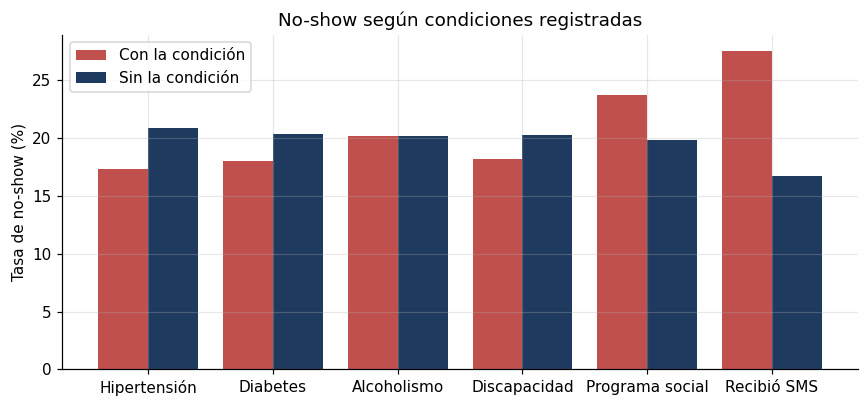

In [7]:
conds = {'Hipertension':'Hipertensión','Diabetes':'Diabetes','Alcoholism':'Alcoholismo','Handcap':'Discapacidad','Scholarship':'Programa social','SMS_received':'Recibió SMS'}
filas = [(v, 100*df.loc[df[k]==1,'no_show'].mean(), 100*df.loc[df[k]==0,'no_show'].mean()) for k,v in conds.items()]
x = np.arange(len(filas)); fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(x-0.2, [f[1] for f in filas], 0.4, label='Con la condición', color=C2); ax.bar(x+0.2, [f[2] for f in filas], 0.4, label='Sin la condición', color=C1)
ax.set_xticks(x, [f[0] for f in filas]); ax.set_ylabel('Tasa de no-show (%)'); ax.legend(); ax.set_title('No-show según condiciones registradas')
guardar('03_condiciones.png')

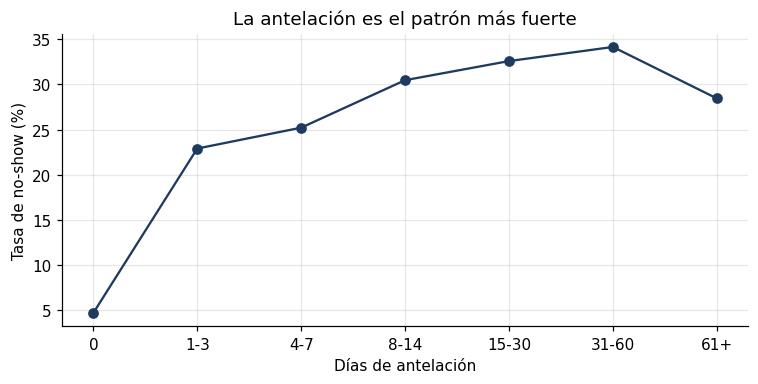

,mean,size
lead_time_days,,
0,0.046594,38567
1-3,0.228893,14675
4-7,0.252027,17510
8-14,0.304699,12025
15-30,0.325888,17371
31-60,0.341543,8283
61+,0.284487,2095


In [8]:
tr = pd.cut(df.lead_time_days, [-1,0,3,7,14,30,60,400], labels=['0','1-3','4-7','8-14','15-30','31-60','61+'])
t = df.groupby(tr, observed=True)['no_show'].agg(['mean','size'])
fig, ax = plt.subplots(figsize=(7, 3.6)); ax.plot(t.index.astype(str), 100*t['mean'], 'o-', color=C1)
ax.set_xlabel('Días de antelación'); ax.set_ylabel('Tasa de no-show (%)'); ax.set_title('La antelación es el patrón más fuerte')
guardar('04_antelacion.png'); t

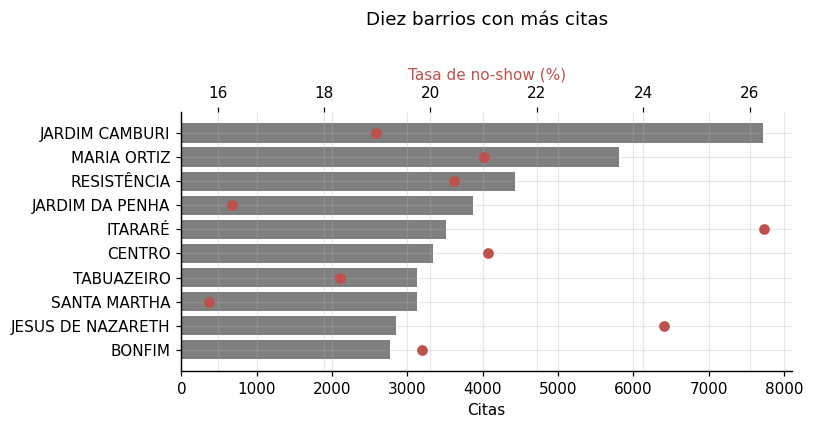

In [9]:
top = df.Neighbourhood.value_counts().head(10).index
t = df[df.Neighbourhood.isin(top)].groupby('Neighbourhood')['no_show'].agg(['mean','size']).sort_values('size')
fig, ax = plt.subplots(figsize=(7.5, 4)); ax.barh(t.index, t['size'], color=C3)
ax2 = ax.twiny(); ax2.plot(100*t['mean'], t.index, 'o', color=C2); ax2.set_xlabel('Tasa de no-show (%)', color=C2)
ax.set_xlabel('Citas'); ax.set_title('Diez barrios con más citas', pad=28)
guardar('05_barrios.png')

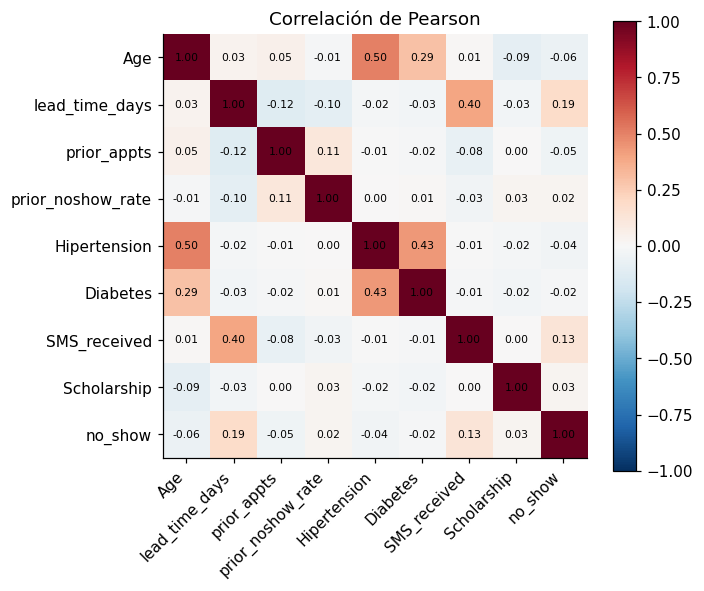

In [10]:
num = df[['Age','lead_time_days','prior_appts','prior_noshow_rate','Hipertension','Diabetes','SMS_received','Scholarship','no_show']]
corr = num.corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5)); im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right'); ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)): ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im); ax.set_title('Correlación de Pearson'); ax.grid(False)
guardar('06_correlacion.png')

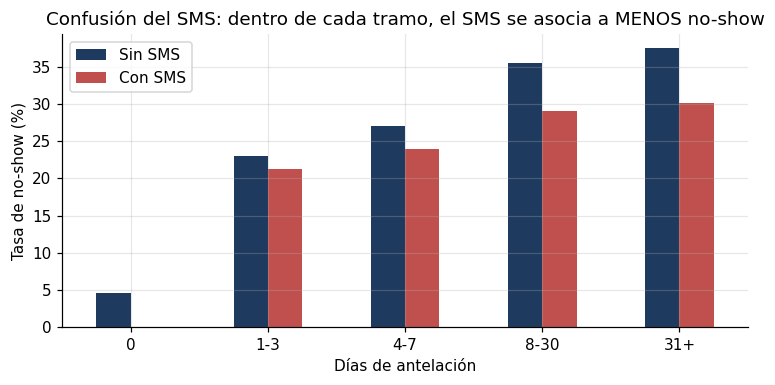

SMS_received,0,1
lead_time_days,,
0,4.7,NaN
1-3,23.0,21.3
4-7,27.1,24.0
8-30,35.6,29.1
31+,37.5,30.2


In [11]:
tr2 = pd.cut(df.lead_time_days, [-1,0,3,7,30,400], labels=['0','1-3','4-7','8-30','31+'])
t = df.groupby([tr2,'SMS_received'], observed=True)['no_show'].mean().unstack()*100
ax = t.plot(kind='bar', figsize=(7,3.6), color=[C1, C2], rot=0)
ax.set_xlabel('Días de antelación'); ax.set_ylabel('Tasa de no-show (%)'); ax.legend(['Sin SMS','Con SMS']); ax.set_title('Confusión del SMS: dentro de cada tramo, el SMS se asocia a MENOS no-show')
guardar('07_sms_confusion.png'); t.round(1)

In [12]:
outliers = {'edad_q99': float(df.Age.quantile(.99)), 'antelacion_q99': float(df.lead_time_days.quantile(.99)), 'antelacion_max': int(df.lead_time_days.max()),
            'citas_por_paciente_max': int(df.PatientId.value_counts().max())}
guardar_json({'calidad': calidad, 'outliers': outliers, 'prevalencia': float(df.no_show.mean()), 'barrios': int(df.Neighbourhood.nunique())}, MET/'eda.json'); outliers

{'edad_q99': 86.0,
 'antelacion_q99': 68.0,
 'antelacion_max': 179,
 'citas_por_paciente_max': 88}

## Hallazgos
1. La **antelación** es el patrón más fuerte: el no-show pasa de 4.7% en citas del mismo día a más de 30% con más de un mes.
2. Los pacientes con condiciones crónicas faltan **menos** (probable vínculo más frecuente con el sistema); el programa social se asocia a **más** inasistencia.
3. El SMS parece asociarse a más no-show, pero es **confusión**: se envía a citas con más antelación. Dentro de cada tramo, el patrón se invierte.
4. Hay variación entre barrios (16% a 26%), que motiva la frecuencia del barrio como variable de control.
5. Desbalance moderado: 20.2% de no-show.